# Bank Marketing Dataset Analysis

## 1. Dataset Inspection

This notebook explores the Bank Marketing dataset
obtained from the UCI Machine Learning Repository.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define the dataset path
file_path = Path("../dataset/raw/bank-full.csv")

# Load the dataset
df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
#Check dataset dimensions
print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])

Number of records: 45211
Number of attributes: 17


In [ ]:
#Display the first five records
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
#Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [ ]:
#Descriptive Statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [ ]:
#Missing Values
missing_values = df.isnull().sum()

print(missing_values)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [ ]:
#Target Variable Distribution
print(df["y"].value_counts())

print("\nPercentage distribution:")
print(df["y"].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64

Percentage distribution:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [9]:
# Check actual missing values
print("Missing values:")
print(df.isnull().sum())

# Check unknown values in categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns

print("\nUnknown values:")

for col in categorical_columns:
    unknown_count = (
        df[col].astype(str).str.lower() == "unknown"
    ).sum()

    if unknown_count > 0:
        percentage = (unknown_count / len(df)) * 100

        print(f"{col}: {unknown_count} ({percentage:.2f}%)")

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Unknown values:
job: 288 (0.64%)
education: 1857 (4.11%)
contact: 13020 (28.80%)
poutcome: 36959 (81.75%)


In [10]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", duplicate_count)

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Total records: 45211
Duplicate records: 0
Duplicate percentage: 0.00%


In [12]:
pd.crosstab(df["previous"] == 0, df["poutcome"])

poutcome,failure,other,success,unknown
previous,,,,
False,4901,1840,1511,5
True,0,0,0,36954


In [13]:
# Descriptive statistics for numerical features
numerical_stats = df.describe().T

print("Descriptive Statistics:")
display(numerical_stats)

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


## 2.5 Numerical Feature Distribution Analysis

Histograms are used to examine the distribution
of numerical attributes in the dataset.

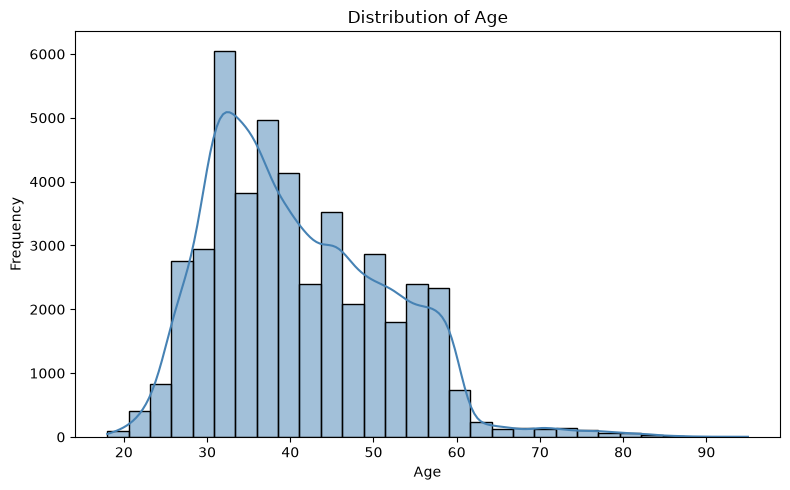

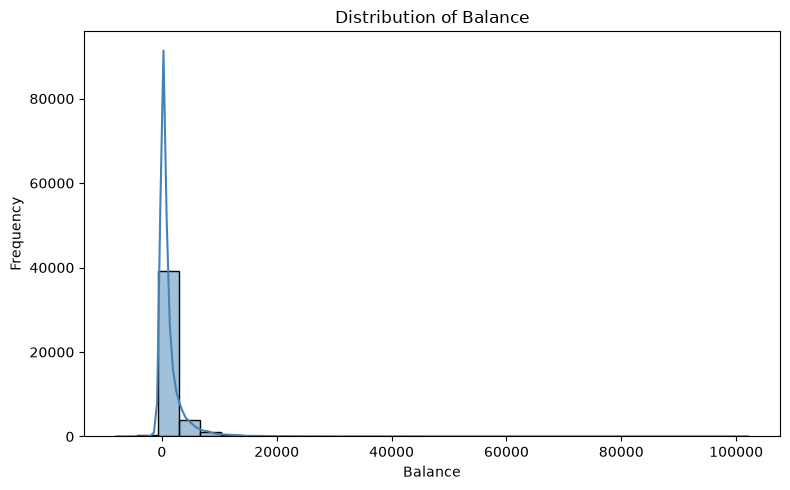

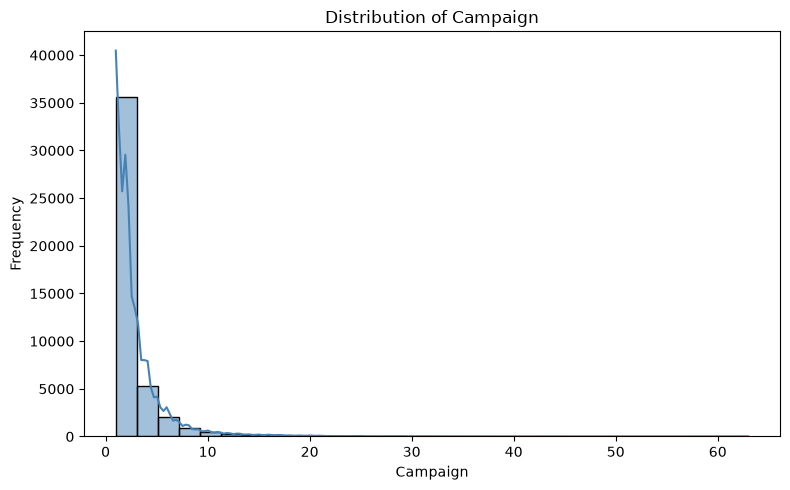

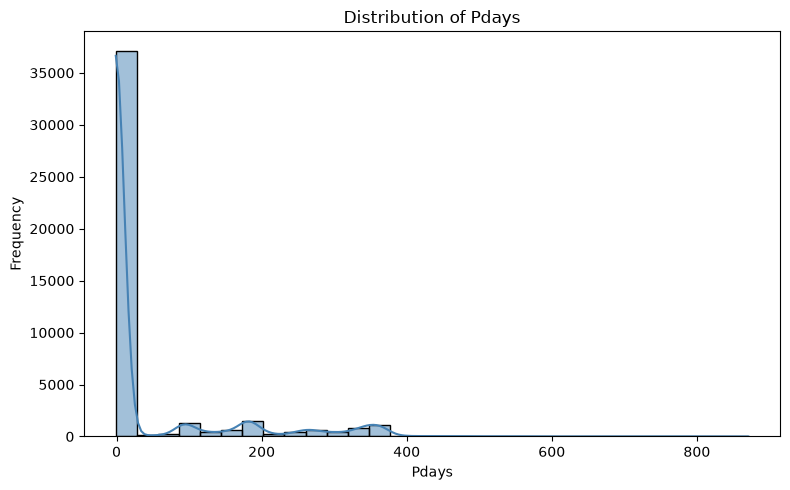

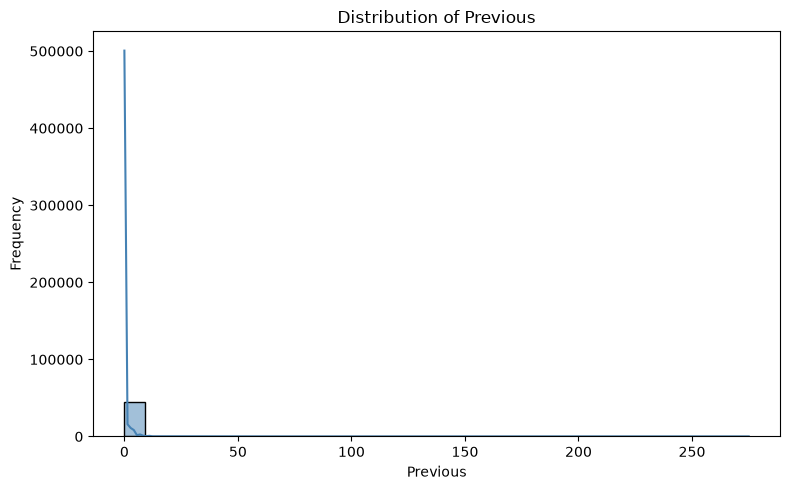

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Numerical features to analyse
numerical_columns = [
    "age",
    "balance",
    "campaign",
    "pdays",
    "previous"
]

# Folder to save diagrams
output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Generate each histogram separately
for col in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        color="steelblue"
    )

    plt.title(f"Distribution of {col.capitalize()}")
    plt.xlabel(col.capitalize())
    plt.ylabel("Frequency")

    plt.tight_layout()

    # Save each histogram individually
    plt.savefig(
        output_dir / f"{col}_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 2.6 Outlier Analysis

Boxplots are used to identify potential outliers
in the numerical attributes.

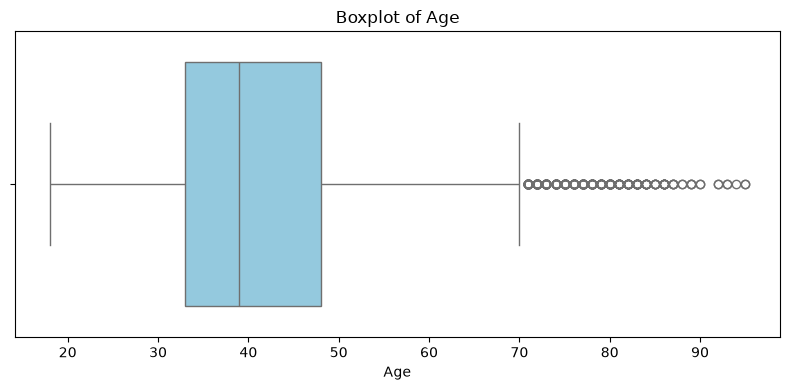

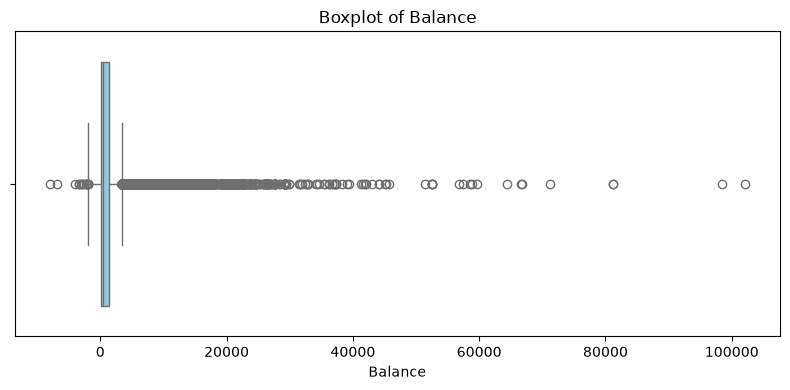

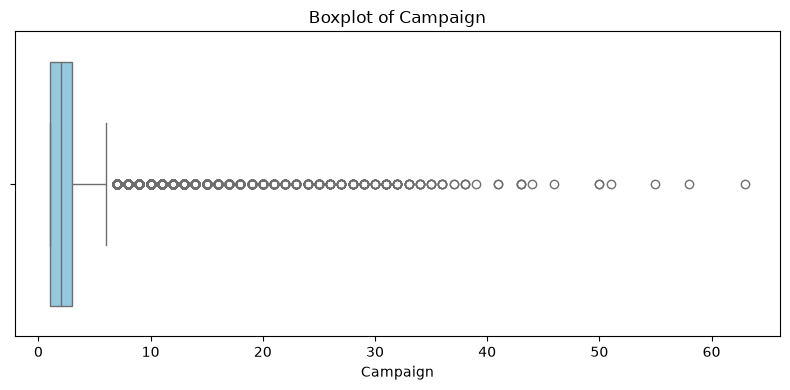

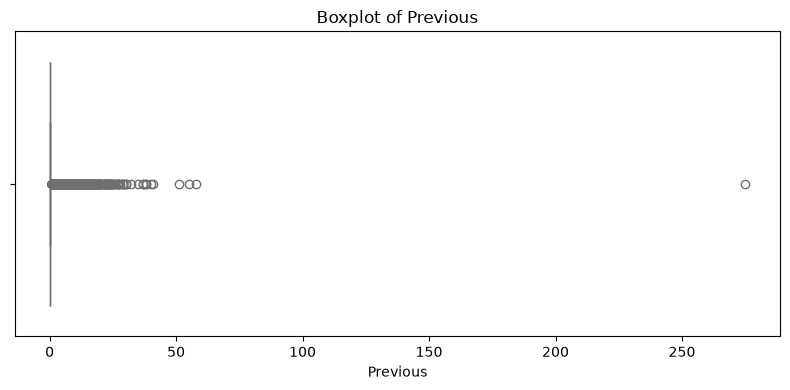

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Numerical features for outlier analysis
numerical_columns = [
    "age",
    "balance",
    "campaign",
    "previous"
]

# Folder for saving boxplots
output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Generate separate boxplots
for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[col],
        color="skyblue"
    )

    plt.title(f"Boxplot of {col.capitalize()}")
    plt.xlabel(col.capitalize())

    plt.tight_layout()

    plt.savefig(
        output_dir / f"{col}_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [17]:
for col in ["age", "balance", "campaign", "previous"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower) | (df[col] > upper)
    ).sum()

    percentage = outlier_count / len(df) * 100

    print(
        f"{col}: {outlier_count} potential outliers "
        f"({percentage:.2f}%)"
    )

age: 487 potential outliers (1.08%)
balance: 4729 potential outliers (10.46%)
campaign: 3064 potential outliers (6.78%)
previous: 8257 potential outliers (18.26%)


## 2.7 Categorical Feature Distribution Analysis

This section analyses the distribution of categorical
features using count plots.

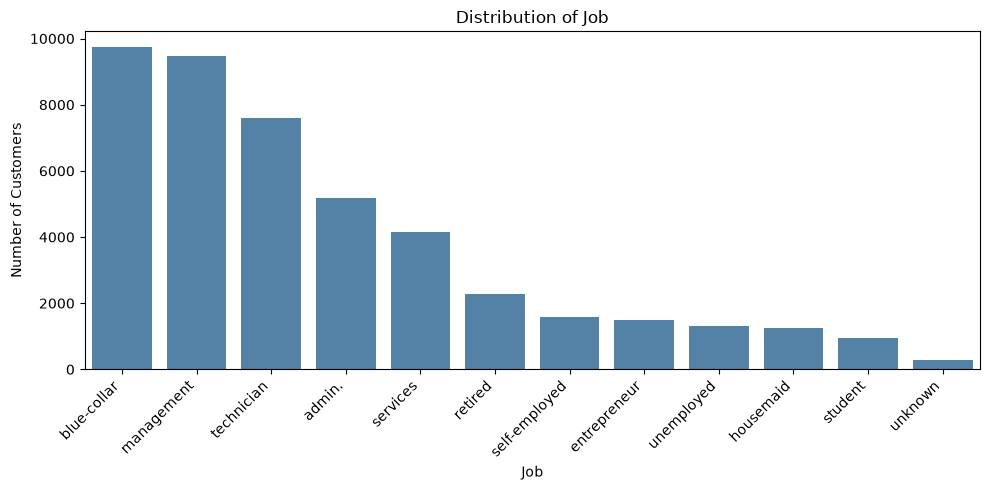

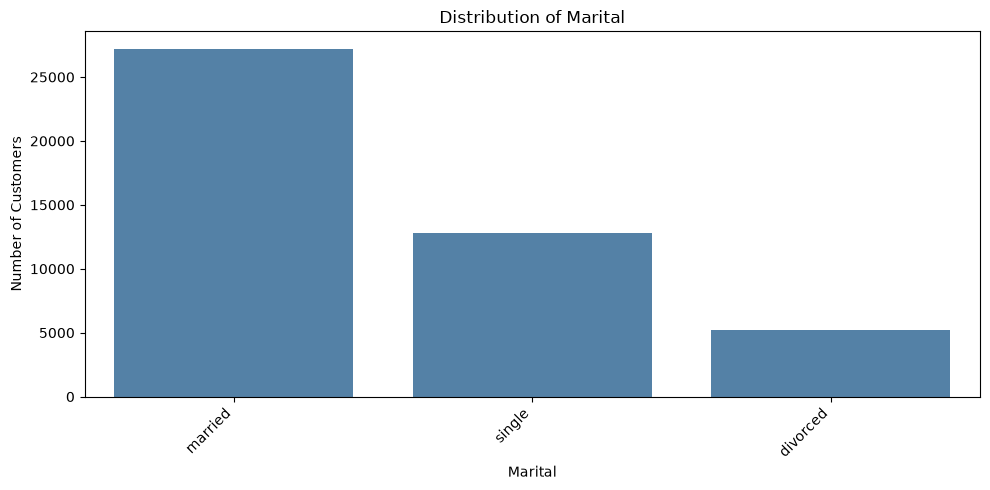

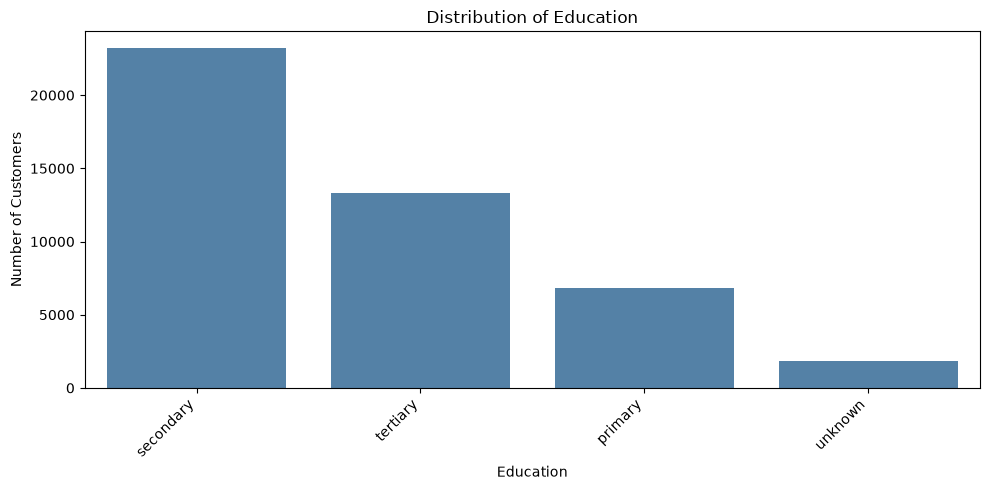

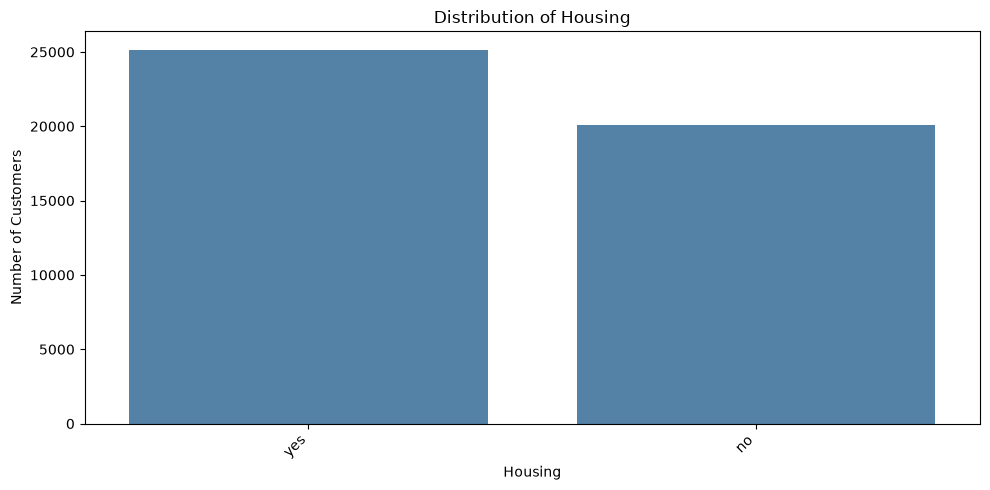

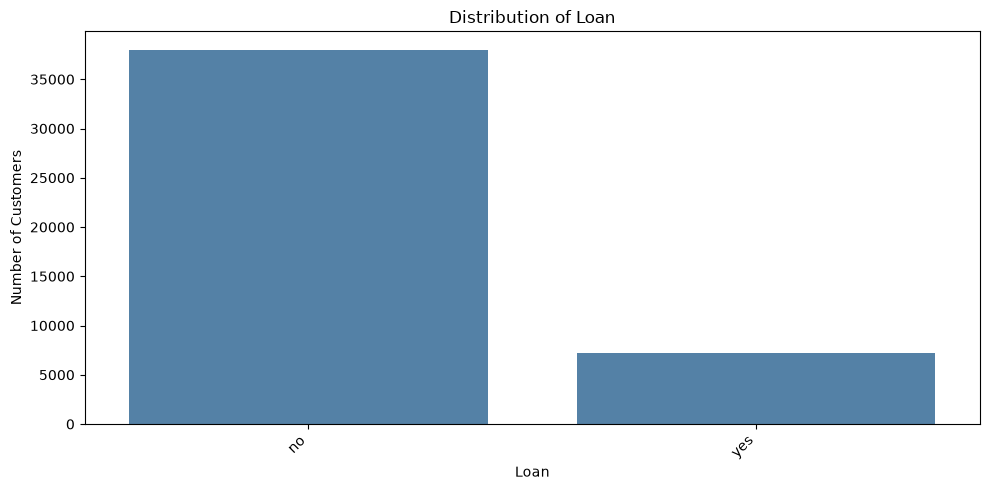

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

categorical_columns = [
    "job",
    "marital",
    "education",
    "housing",
    "loan"
]

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

for col in categorical_columns:

    plt.figure(figsize=(10, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        color="steelblue"
    )

    plt.title(f"Distribution of {col.capitalize()}")
    plt.xlabel(col.capitalize())
    plt.ylabel("Number of Customers")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        output_dir / f"{col}_categorical_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [19]:
for col in categorical_columns:

    print(f"\n===== {col.upper()} =====")

    summary = pd.DataFrame({
        "Count": df[col].value_counts(),
        "Percentage (%)": (
            df[col].value_counts(normalize=True) * 100
        ).round(2)
    })

    display(summary)


===== JOB =====


,Count,Percentage (%)
job,,
blue-collar,9732,21.53
management,9458,20.92
technician,7597,16.80
admin.,5171,11.44
services,4154,9.19
retired,2264,5.01
self-employed,1579,3.49
entrepreneur,1487,3.29
unemployed,1303,2.88



===== MARITAL =====


,Count,Percentage (%)
marital,,
married,27214,60.19
single,12790,28.29
divorced,5207,11.52



===== EDUCATION =====


,Count,Percentage (%)
education,,
secondary,23202,51.32
tertiary,13301,29.42
primary,6851,15.15
unknown,1857,4.11



===== HOUSING =====


,Count,Percentage (%)
housing,,
yes,25130,55.58
no,20081,44.42



===== LOAN =====


,Count,Percentage (%)
loan,,
no,37967,83.98
yes,7244,16.02


## 2.8 Correlation Analysis

Pearson correlation is used to examine linear
relationships between numerical attributes.

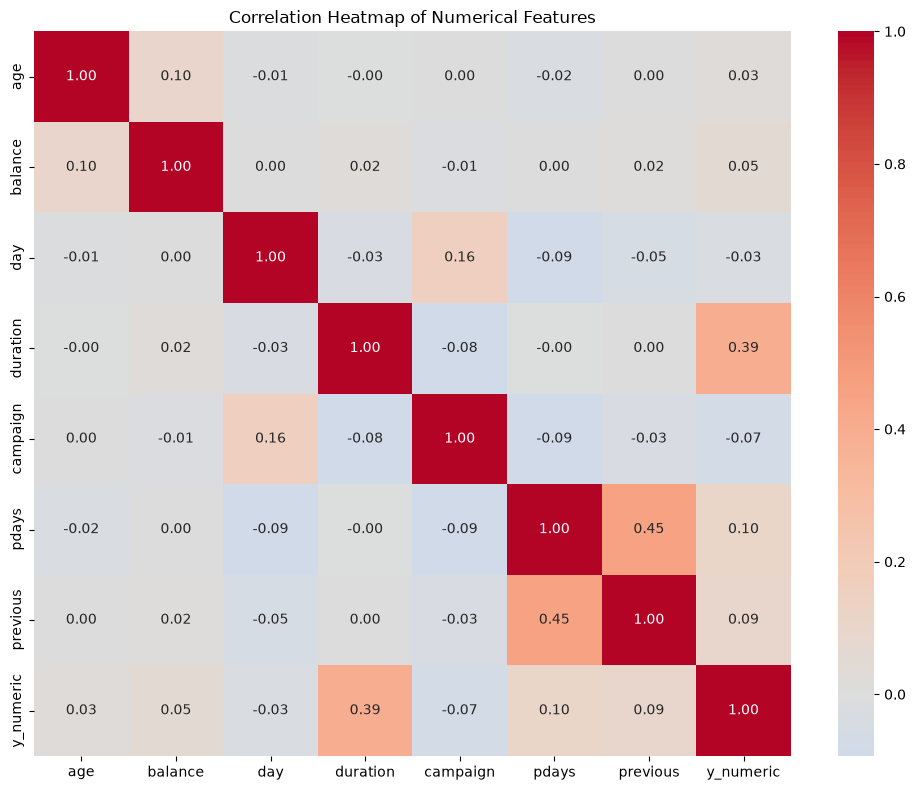

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create a copy for correlation analysis
correlation_df = df.copy()

# Convert target variable to numerical values
correlation_df["y_numeric"] = (
    correlation_df["y"].map({"no": 0, "yes": 1})
)

# Select numerical columns
numerical_features = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous",
    "y_numeric"
]

# Calculate Pearson correlation
correlation_matrix = (
    correlation_df[numerical_features].corr()
)

# Create heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

# Save figure
output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 2.9 Relationship Between Customer Features and Subscription

This section compares subscription rates across
different customer groups.

In [21]:
# Features to investigate
features = [
    "job",
    "marital",
    "education",
    "housing",
    "loan"
]

for col in features:

    print(f"\n===== {col.upper()} =====")

    subscription_rate = (
        df.groupby(col)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    display(subscription_rate.round(2))


===== JOB =====


job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: y, dtype: float64


===== MARITAL =====


marital
single      14.95
divorced    11.95
married     10.12
Name: y, dtype: float64


===== EDUCATION =====


education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: y, dtype: float64


===== HOUSING =====


housing
no     16.7
yes     7.7
Name: y, dtype: float64


===== LOAN =====


loan
no     12.66
yes     6.68
Name: y, dtype: float64

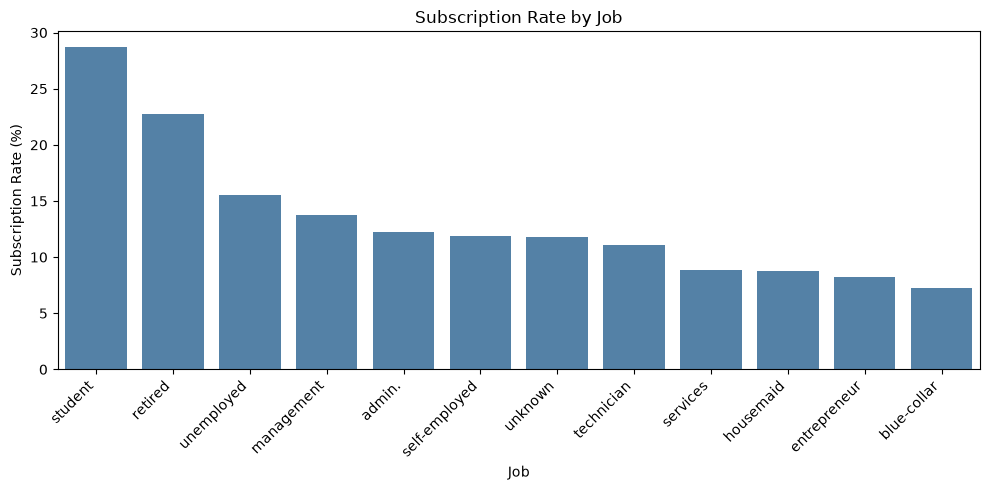

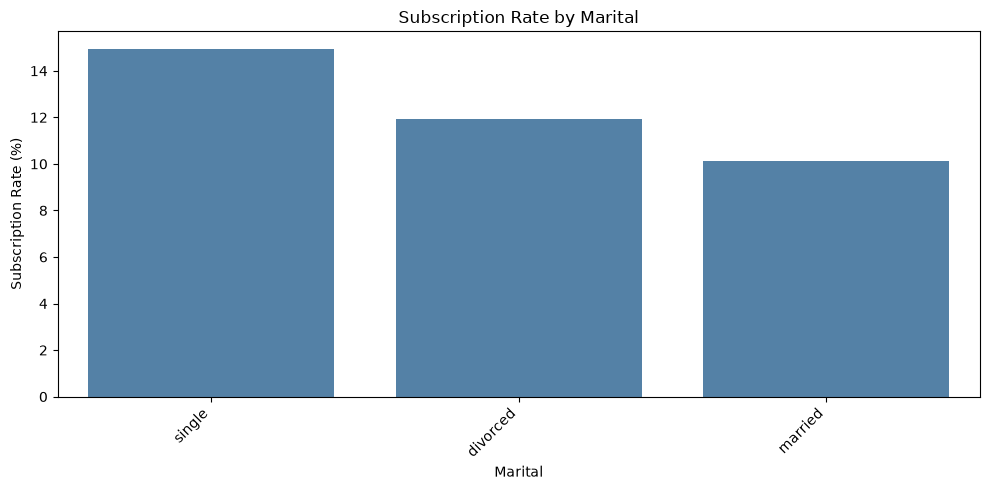

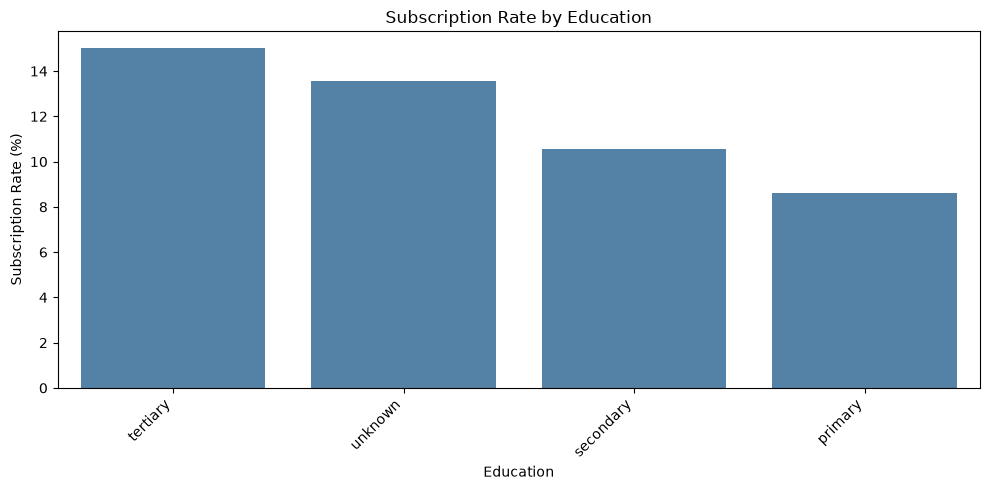

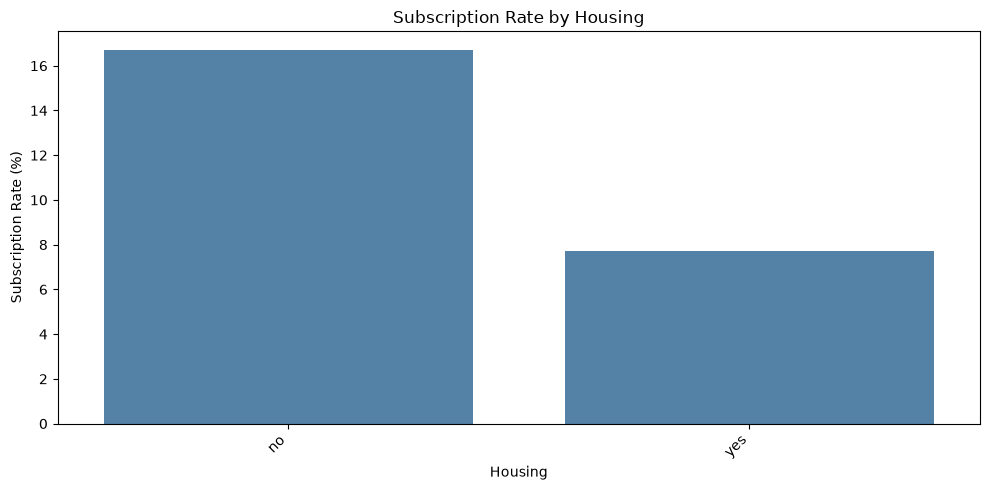

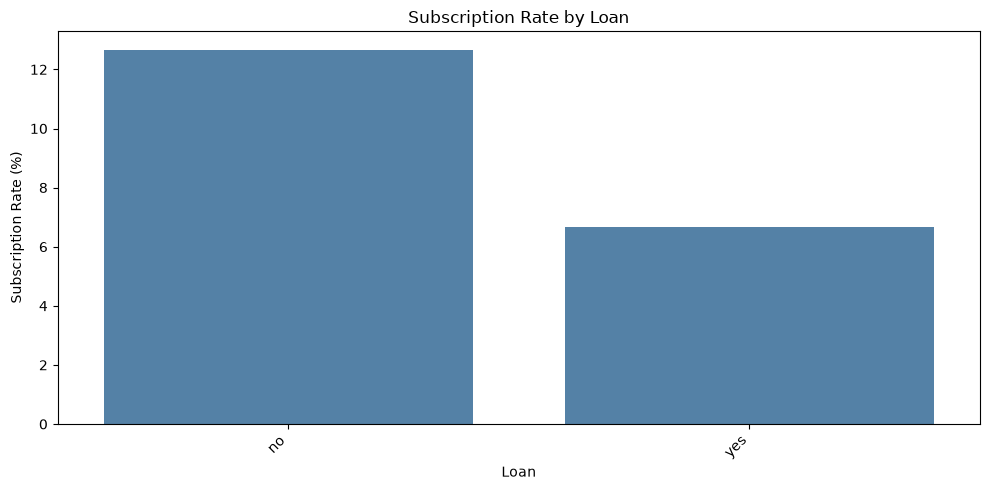

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

for col in features:

    subscription_rate = (
        df.groupby(col)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=subscription_rate.index,
        y=subscription_rate.values,
        color="steelblue"
    )

    plt.title(f"Subscription Rate by {col.capitalize()}")
    plt.xlabel(col.capitalize())
    plt.ylabel("Subscription Rate (%)")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    plt.savefig(
        output_dir / f"{col}_subscription_rate.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()